### Codes from https://github.com/bradlipovsky/wedge/blob/main/stagnation.ipynb

In [1]:
import firedrake
import numpy as np
import pickle as pkl
from numpy import pi as π
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import firedrake
from firedrake import Constant, inner, sqrt, tr, grad, div, as_vector, exp,sym, as_vector, dx, ds, Mesh, Function, project, TransferManager
import meshpy, meshpy.geometry, meshpy.triangle
import irksome
from irksome import Dt
from scipy.signal import detrend
import copy
import matplotlib
import irksome
from irksome import Dt
import matplotlib.pyplot as plt
import pandas as pd
import scipy
import pickle as pkl
import tqdm
import emcee
import corner
import itertools
import xarray
import dtscalibration
import glob
from rasterio.plot import show
import matplotlib.colors as mcolors
import matplotlib.cm as cm
import os
import sys
from pyproj import Transformer
module_path = os.path.abspath(os.path.join('..'))
if module_path not in sys.path:
    sys.path.append(module_path)

from scripts.AH_temp_funcs import *
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from mpl_toolkits.basemap import Basemap
import shapefile as sf

import rasterio
from rasterio.enums import Resampling
from rasterio.mask import mask

from firedrake.checkpointing import DumbCheckpoint

from firedrake import *

### Import our homemade functions ###
import scripts.model_modules
from scripts.mesh_generating import *

import cartopy.crs as ccrs

%matplotlib widget

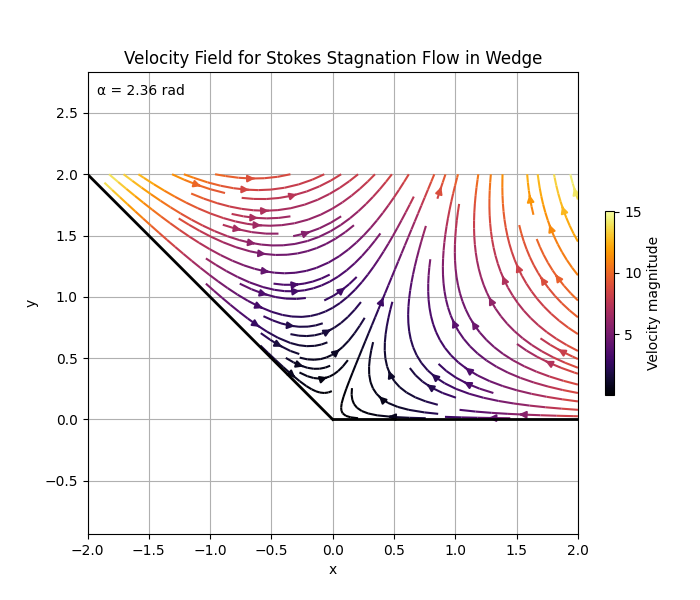

In [5]:
# Parameters
A = -1.0               # Streamfunction amplitude
alpha =3*np.pi / 4     # Wedge angle in radians (change as needed)

# Create Cartesian grid
x = np.linspace(-2, 2, 300)
y = np.linspace(0.01, 2.0, 300)  # Stay within wedge (upper half-plane)
Xc, Yc = np.meshgrid(x, y)

# Convert to polar coordinates
Rc = np.sqrt(Xc**2 + Yc**2)
Thetac = np.arctan2(Yc, Xc)

# Mask points outside the wedge (θ ∉ (0, α))
mask = (Thetac <= 0) | (Thetac >= alpha)
Rc[mask] = np.nan
Thetac[mask] = np.nan

# Compute velocity components in polar coordinates
dpsi_dtheta = A * Rc**(2 * np.pi / alpha) * (2 * np.pi / alpha) * np.cos((2 * np.pi / alpha) * Thetac)
dpsi_dr = A * (2 * np.pi / alpha) * Rc**(2 * np.pi / alpha - 1) * np.sin((2 * np.pi / alpha) * Thetac)

u_r = (1 / Rc) * dpsi_dtheta
u_theta = -dpsi_dr

# Convert to Cartesian components
u_x = u_r * np.cos(Thetac) - u_theta * np.sin(Thetac)
u_y = u_r * np.sin(Thetac) + u_theta * np.cos(Thetac)

# Plot the velocity field
plt.figure(figsize=(7, 6))

plt.streamplot(x, y, u_x, u_y, color=np.sqrt(u_x**2 + u_y**2), cmap='inferno', density=1)

plt.plot([0, plt.ylim()[1]], [0, 0], 'k-', lw=2)  # Wedge boundary
plt.plot([plt.xlim()[0], 0], [plt.xlim()[0]*np.tan(alpha), 0], 'k-', lw=2)  # Wedge boundary

plt.annotate(f'α = {alpha:.2f} rad', xy=(0.02,0.95), xycoords='axes fraction')

plt.title(f"Velocity Field for Stokes Stagnation Flow in Wedge")
plt.xlabel("x")
plt.ylabel("y")
plt.axis('equal')
plt.grid(True)
plt.colorbar(label='Velocity magnitude', fraction=0.046, shrink=0.4)
plt.savefig('Figures/figs1.png',dpi=600)
plt.show()